## 1.数据集的导入

In [1]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
housing = fetch_california_housing()
print(housing.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])


In [2]:
housing['data'].shape

(20640, 8)

In [3]:
print(housing['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

## 2.用线性回归模型拟合数据进行预测

In [4]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(housing['data'],housing['target'],random_state=36)

lr_housing = LinearRegression()

lr_housing.fit(X_train,y_train)

y_predict = lr_housing.predict(X_test)

## 3.评估

In [5]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test,y_predict)
print('均方误差：',mse)

均方误差： 0.5353872882278597


## 4.输出线性回归模型的系数和偏置

In [6]:
print('lr_housing.coef_:{}'.format(lr_housing.coef_[:]))
print('lr_housing.intercept_:{}'.format(lr_housing.intercept_))

lr_housing.coef_:[ 4.32980690e-01  9.45143861e-03 -1.00257981e-01  6.15927020e-01
 -5.55863361e-06 -3.32881862e-03 -4.29628533e-01 -4.42880170e-01]
lr_housing.intercept_:-37.636736787314454


## 5.绘制加利福利亚房价与预测房价


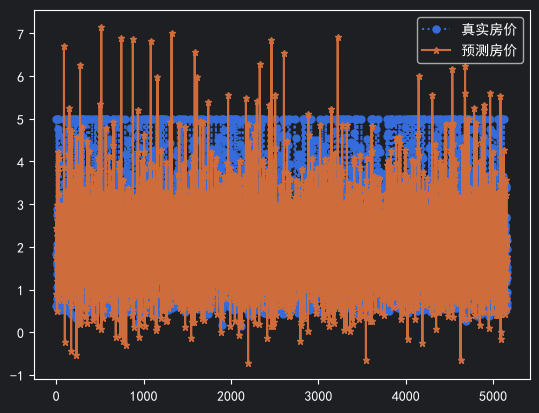

In [14]:
plt.figure()
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False
x = np.arange(1,y_predict.shape[0]+1)
plt.plot(x,y_test,marker='o',linestyle=':',markersize=5)
plt.plot(x,y_predict,marker='*',markersize=5)
plt.legend(['真实房价','预测房价'])
plt.show()

# 岭回归模型的应用

In [15]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0)
ridge.fit(X_train,y_train)
y_predict_ridge = ridge.predict(X_test)

print('ridge.coef_:{}'.format(ridge.coef_[:]))
print('ridge.intercept_:{}'.format(ridge.intercept_))

ridge.coef_:[ 4.32858633e-01  9.45356175e-03 -1.00021618e-01  6.14674643e-01
 -5.55084423e-06 -3.32853858e-03 -4.29603312e-01 -4.42836491e-01]
ridge.intercept_:-37.63192293360041


In [16]:
mse_rid = mean_squared_error(y_test,y_predict_ridge)
print('岭回归模型均方误差为',mse_rid)

岭回归模型均方误差为 0.535393986309559


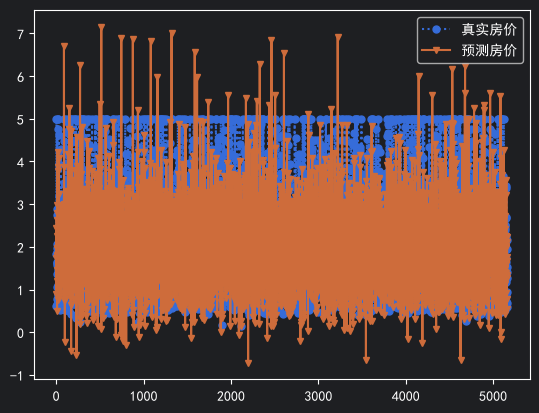

In [18]:
plt.figure()
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False
x = np.arange(1,y_predict.shape[0]+1)
plt.plot(x,y_test,marker='o',linestyle=':',markersize=5)
plt.plot(x,y_predict_ridge,marker='v',markersize=5)
plt.legend(['真实房价','预测房价'])

# 套索回归模型的应用

In [11]:
from sklearn.linear_model import Lasso
lasso = Lasso()
lasso.fit(X_train,y_train)
y_predict_lasso = lasso.predict(X_test)

print('lasso.coef_:{}'.format(lasso.coef_[:]))
print('lasso.intercept_:{}'.format(lasso.intercept_))

lasso.coef_:[ 1.52193489e-01  5.88790995e-03  0.00000000e+00  0.00000000e+00
 -1.06529292e-05 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00]
lasso.intercept_:1.3268966139347609


In [12]:
mse_las = mean_squared_error(y_test,y_predict_lasso)
print('套索回归模型的均方误差：',mse_las)

套索回归模型的均方误差： 0.9210151213893154


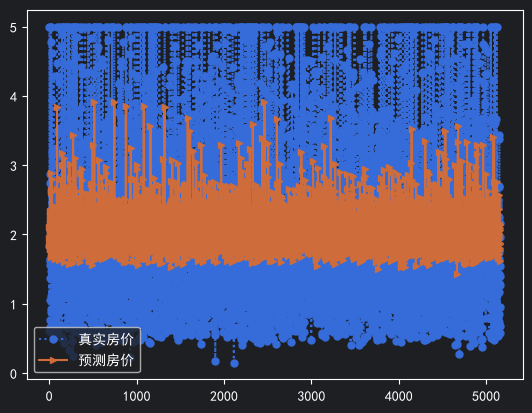

In [19]:
plt.figure()
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False
x = np.arange(1,y_predict.shape[0]+1)
plt.plot(x,y_test,marker='o',linestyle=':',markersize=5)
plt.plot(x,y_predict_lasso,marker='>',markersize=5)
plt.legend(['真实房价','预测房价'])